# 07 · Características por episodio

Construye las variables para el análisis de factores, una fila por episodio de la población de análisis, usando solo información disponible en el momento de la llegada. Los desenlaces llevan el prefijo `y_`.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / 'src' / 'config.py').exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import pandas as pd

from src import caracteristicas as car
from src import config, estilo
from src import ocupacion as oc
from src.db import consultar
from src.graficos import activar_formato_tablas, aplicar_estilo, guardar_figura, titulo_hallazgo
from src.privacidad import tabla_segura
from src.tablas import mostrar_tabla, tabla_medidas

aplicar_estilo()
activar_formato_tablas()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

## 1. Carga

Dataset final de episodios del notebook 05. La tabla de características parte de los episodios de la población de análisis; las variables de historia y de cola usan todos los episodios del dataset.

In [2]:
ruta_episodios = config.DATA_INTERIM / 'episodios_final.parquet'
if not ruta_episodios.exists():
    tabla_medidas({'archivo': 'data/interim/episodios_final.parquet', 'aviso': 'El archivo no existe.',
                   'qué hacer': 'Corre los notebooks 03 y 05 para crear el dataset final.'}, 'Dataset no disponible')
    raise SystemExit('Dataset no disponible: la celda se detiene.')

episodios = pd.read_parquet(ruta_episodios)
DESDE, HASTA = config.FECHA_INICIO_ANALISIS, config.FECHA_CORTE_ANALISIS
poblacion = episodios[episodios['en_poblacion']].copy()
llegada = poblacion['llegada']

caracteristicas = poblacion[list(car.COPIADAS)].copy()
desenlaces = poblacion[list(car.DESENLACES)].rename(columns=car.DESENLACES)

## 2. Calendario

Hora, día de la semana, mes, año, fin de semana, festivo de Colombia y franja horaria de la llegada.

In [3]:
caracteristicas = caracteristicas.join(car.variables_calendario(llegada))

## 3. Edad

Edad a la llegada (año de llegada − año de nacimiento), pediatría (menor de `EDAD_PEDIATRIA`) y grupo de edad según `GRUPOS_EDAD`.

In [4]:
caracteristicas = caracteristicas.join(car.variables_edad(poblacion['edad']))

## 4. Visitas previas

Episodios del mismo paciente con llegada en los 30 y 365 días anteriores, y marca de si esa ventana queda completa dentro de los datos (que empiezan el 2023-01-01).

In [5]:
for dias in config.VENTANAS_HISTORIA_D:
    caracteristicas[f'n_episodios_previos_{dias}d'] = car.episodios_previos(episodios, poblacion, dias)
    caracteristicas[f'historia_completa_{dias}d'] = car.historia_completa(llegada, dias)

## 5. Pacientes en urgencias a la llegada

Episodios de atención en urgencias y hospitalizados presentes en urgencias en el instante exacto de la llegada (inicio anterior y fin posterior, sin contar el propio episodio), y su percentil dentro del censo horario del trimestre. La referencia del percentil excluye el periodo de calentamiento (enero de 2023).

In [6]:
intervalos = oc.intervalos_urgencias(episodios, con_atencion=True, solo_poblacion=False)
presentes = oc.censo_en_instantes(intervalos['inicio'], intervalos['fin'], llegada)
referencia = oc.sin_calentamiento(oc.censo_horario(intervalos['inicio'], intervalos['fin'], DESDE, HASTA))
caracteristicas['urg_atencion_presentes_llegada'] = presentes
caracteristicas['urg_atencion_presentes_llegada_pct_trimestre'] = oc.percentil_en_censo(referencia, presentes, llegada)
caracteristicas['censo_calentamiento'] = llegada.lt(config.FECHA_INICIO_CENSO)

## 6. Ocupación del piso a la llegada

Pacientes en el piso en el instante exacto de la llegada (inicio anterior y fin posterior), igual que urgencias, en total y en el piso del grupo de edad del paciente (adultos o pediatría), con su percentil dentro del censo horario del trimestre.

In [7]:
estancias = oc.preparar_estancias_piso(consultar('06_estancias_piso'), fin_si_falta=HASTA)
piso = oc.fusionar_intervalos(estancias[['person_id', 'inicio', 'fin', 'edad', 'sin_fin', 'fin_fraccion_segundo']])
piso['grupo_edad'] = oc.grupo_edad(piso['edad'])
censos_piso = oc.censos_por_edad(piso, DESDE, HASTA)
referencias_piso = oc.sin_calentamiento(censos_piso)

absoluto, percentil = car.censo_a_la_llegada(piso, referencias_piso['total'], llegada)
caracteristicas['piso_censo_llegada'] = absoluto
caracteristicas['piso_censo_llegada_pct_trimestre'] = percentil
absoluto, percentil = car.censo_de_su_grupo(piso, referencias_piso, llegada, oc.grupo_edad(poblacion['edad']))
caracteristicas['piso_grupo_censo_llegada'] = absoluto
caracteristicas['piso_grupo_censo_llegada_pct_trimestre'] = percentil

## 7. LOS reciente

Promedio y mediana del LOS de los episodios de atención en urgencias y hospitalizados que salieron de urgencias en las `VENTANA_LOS_RECIENTE_H` horas anteriores a la llegada, y número de esas salidas. Sin salidas, el promedio y la mediana quedan vacíos.

In [8]:
caracteristicas = caracteristicas.join(car.los_reciente(episodios, llegada, config.VENTANA_LOS_RECIENTE_H))
caracteristicas = caracteristicas.join(desenlaces)

PREDICTORES = car.columnas_con_rol('predictor')
DESENLACES = car.columnas_con_rol('desenlace')
OTRAS = car.columnas_con_rol('estrato', 'descriptiva', 'control')

## 8. Revisión de las características

### 8.1 Resumen por variable

Tipo, % faltante, mínimo, mediana, máximo y número de categorías de cada predictor y, en una tabla aparte, de los estratos, las variables descriptivas, los controles y los desenlaces, con su rol según `ROLES_CARACTERISTICAS`.

In [9]:
mostrar_tabla(car.resumen_variables(caracteristicas, PREDICTORES).round(2), 'Predictores: resumen por variable')

otras = car.resumen_variables(caracteristicas, OTRAS + DESENLACES).round(2)
otras.insert(0, 'rol', [config.ROLES_CARACTERISTICAS[c] for c in otras.index])
mostrar_tabla(otras, 'Estratos, descriptivas, controles y desenlaces: resumen por variable')

**Predictores: resumen por variable**

,tipo,pct_faltante,minimo,mediana,maximo,categorias
variable,,,,,,
sexo,categorica,"0,0",NaN,NaN,NaN,3
hosp_previa_30d,booleana,"0,0",NaN,NaN,NaN,2
hora,numerica,"0,0",0,12,23,NaN
dia_semana,numerica,"0,0",0,3,6,NaN
mes,numerica,"0,0",1,6,12,NaN
anio,numerica,"0,0",2.023,2.024,2.026,NaN
fin_de_semana,booleana,"0,0",NaN,NaN,NaN,2
festivo,booleana,"0,0",NaN,NaN,NaN,2
franja,categorica,"0,0",NaN,NaN,NaN,4


**Estratos, descriptivas, controles y desenlaces: resumen por variable**

,rol,tipo,pct_faltante,minimo,mediana,maximo,categorias
variable,,,,,,,
grupo,estrato,categorica,"0,0",NaN,NaN,NaN,3
nota_consulta_urg,descriptiva,booleana,"0,0",NaN,NaN,NaN,2
n_visitas,descriptiva,numerica,"0,0",1,1,16,NaN
historia_completa_30d,control,booleana,"0,0",NaN,NaN,NaN,2
historia_completa_365d,control,booleana,"0,0",NaN,NaN,NaN,2
censo_calentamiento,control,booleana,"0,0",NaN,NaN,NaN,2
y_los_h,desenlace,numerica,"0,0",0,"0,09","5.625,85",NaN
y_los_mas_12h,desenlace,booleana,"48,8",NaN,NaN,NaN,2
y_reconsulta_72h,desenlace,booleana,"0,0",NaN,NaN,NaN,2


### 8.2 Distribuciones

Histogramas o barras de cada predictor; los intervalos o categorías con menos de 10 episodios no se dibujan.

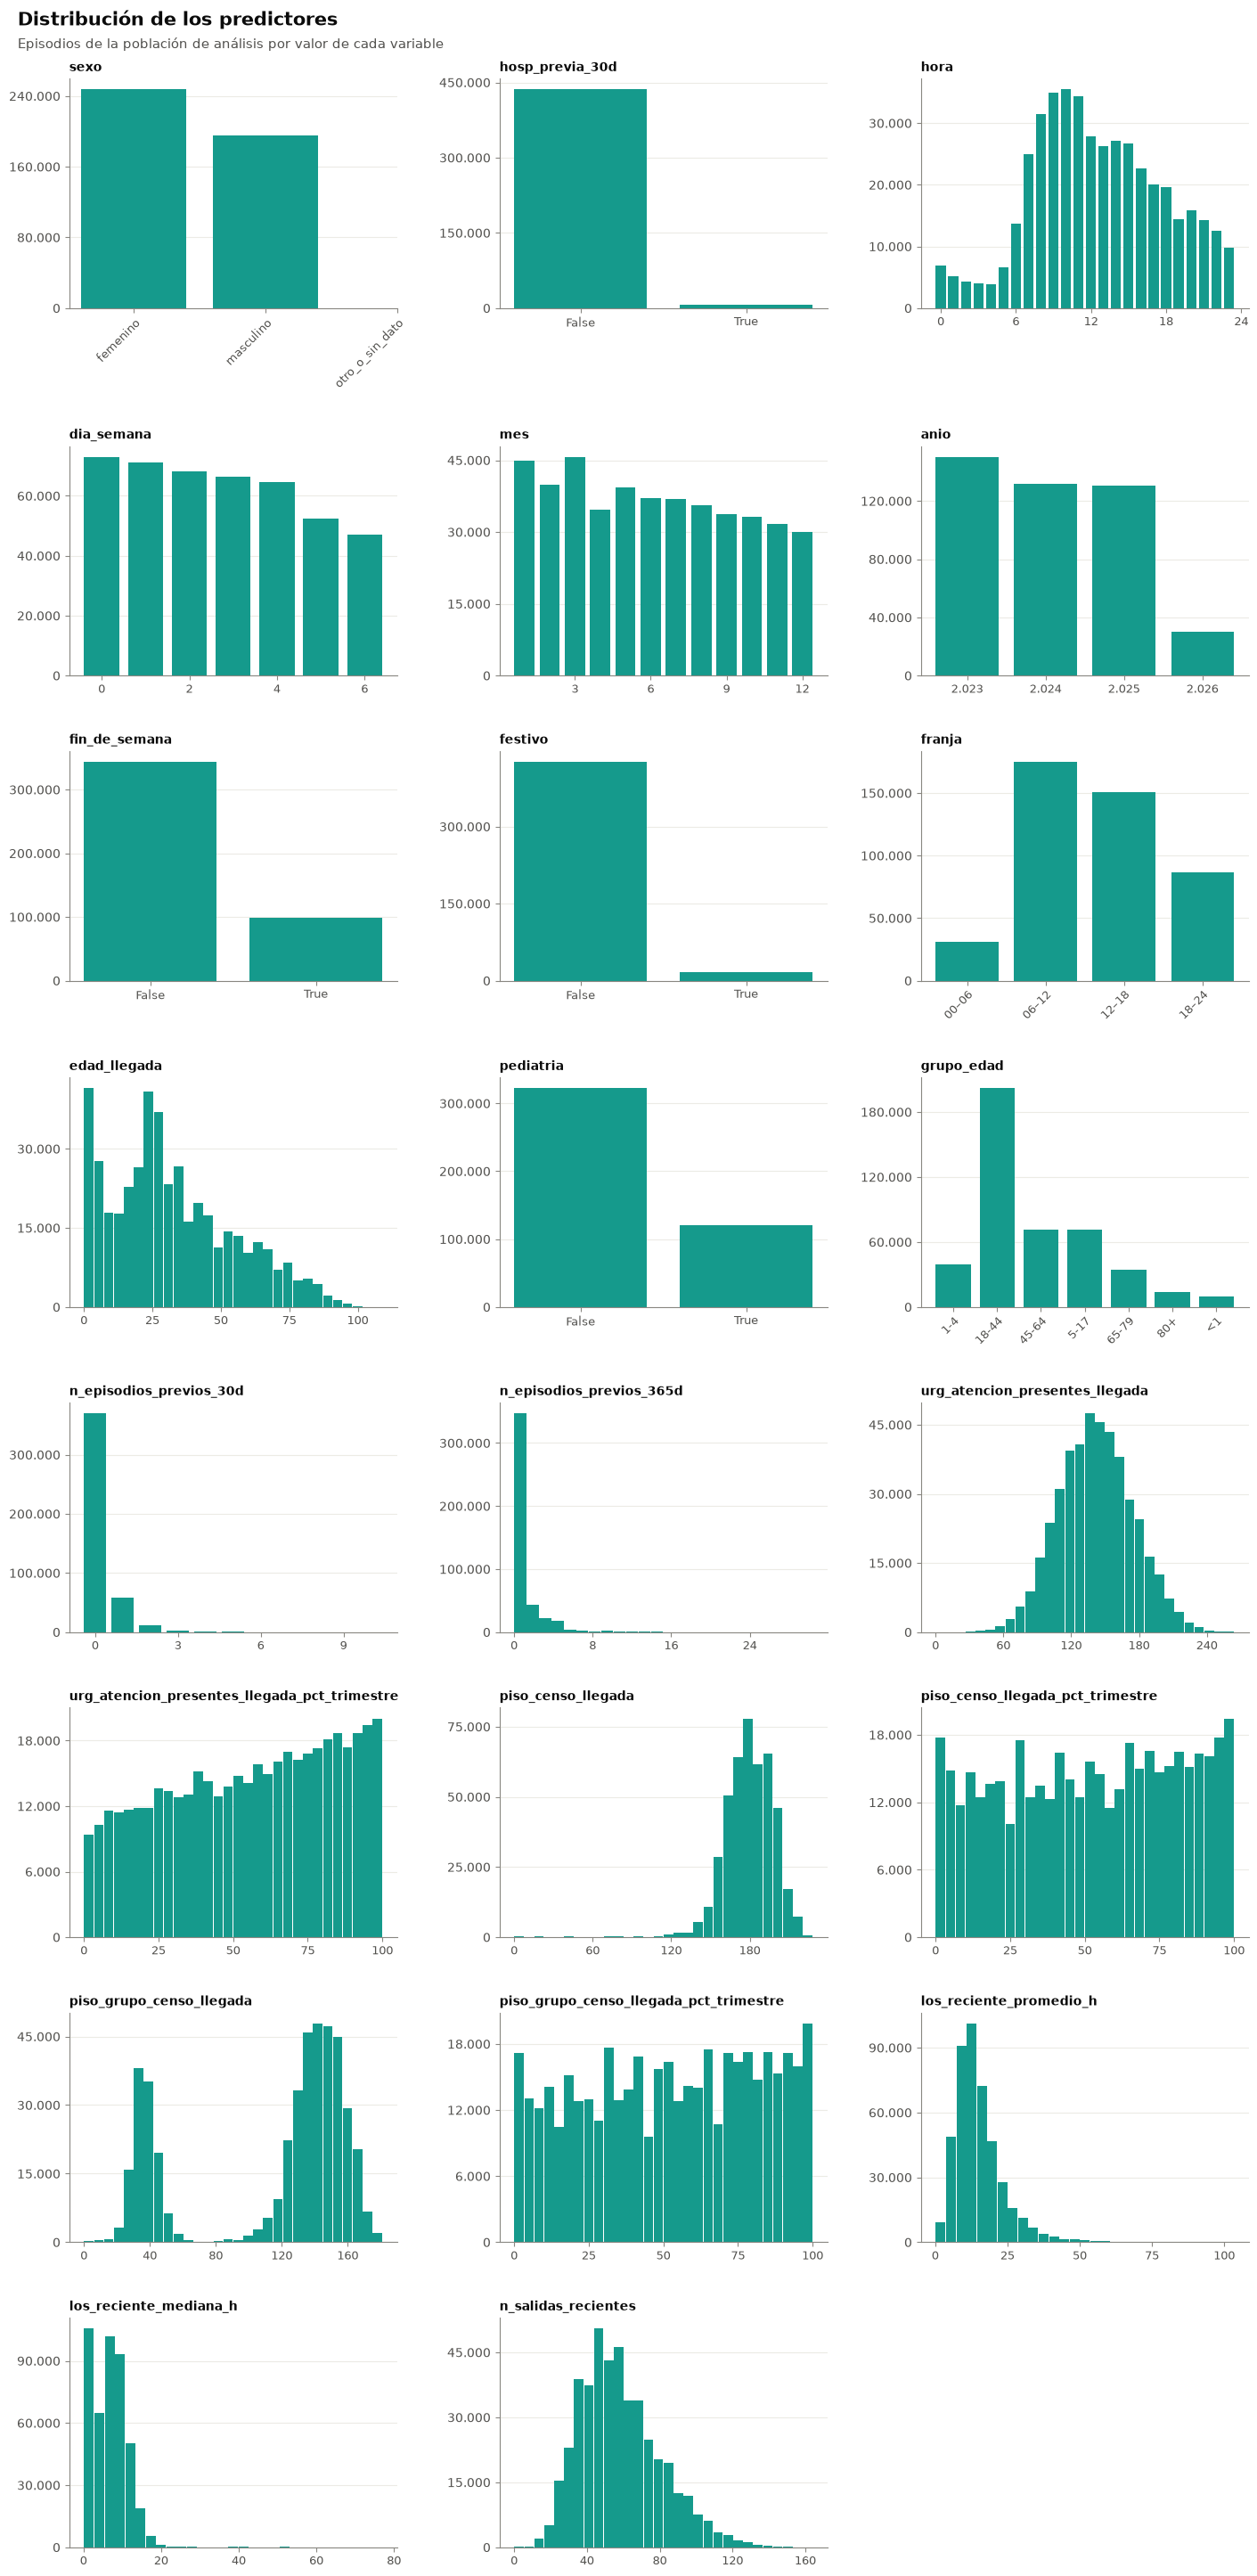

In [10]:
fig = car.graficar_distribuciones(caracteristicas, PREDICTORES, color=estilo.VERDE)
titulo_hallazgo(fig, 'Distribución de los predictores', 'Episodios de la población de análisis por valor de cada variable')
guardar_figura(fig, '07_distribucion_predictores')
plt.show()

### 8.3 Correlación entre las variables numéricas

Correlación de Spearman entre los predictores numéricos.

/var/home/luencaro/Programing/College/2026-30/Data Challenge HUN/patient-flow-HUN/src/graficos.py:655: UserWarning: Figura 07_correlacion_spearman: 17 pares de textos superpuestos, por ejemplo «anio» y «edad_llegada»; «edad_llegada» y «n_episodios_previos_30d»; «n_episodios_previos_30d» y «n_episodios_previos_365d»; «n_episodios_previos_30d» y «urg_atencion_presentes_llegada»; «n_episodios_previos_30d» y «urg_atencion_presentes_llegada_pct_trime».
  revisar_solapes(fig, nombre)


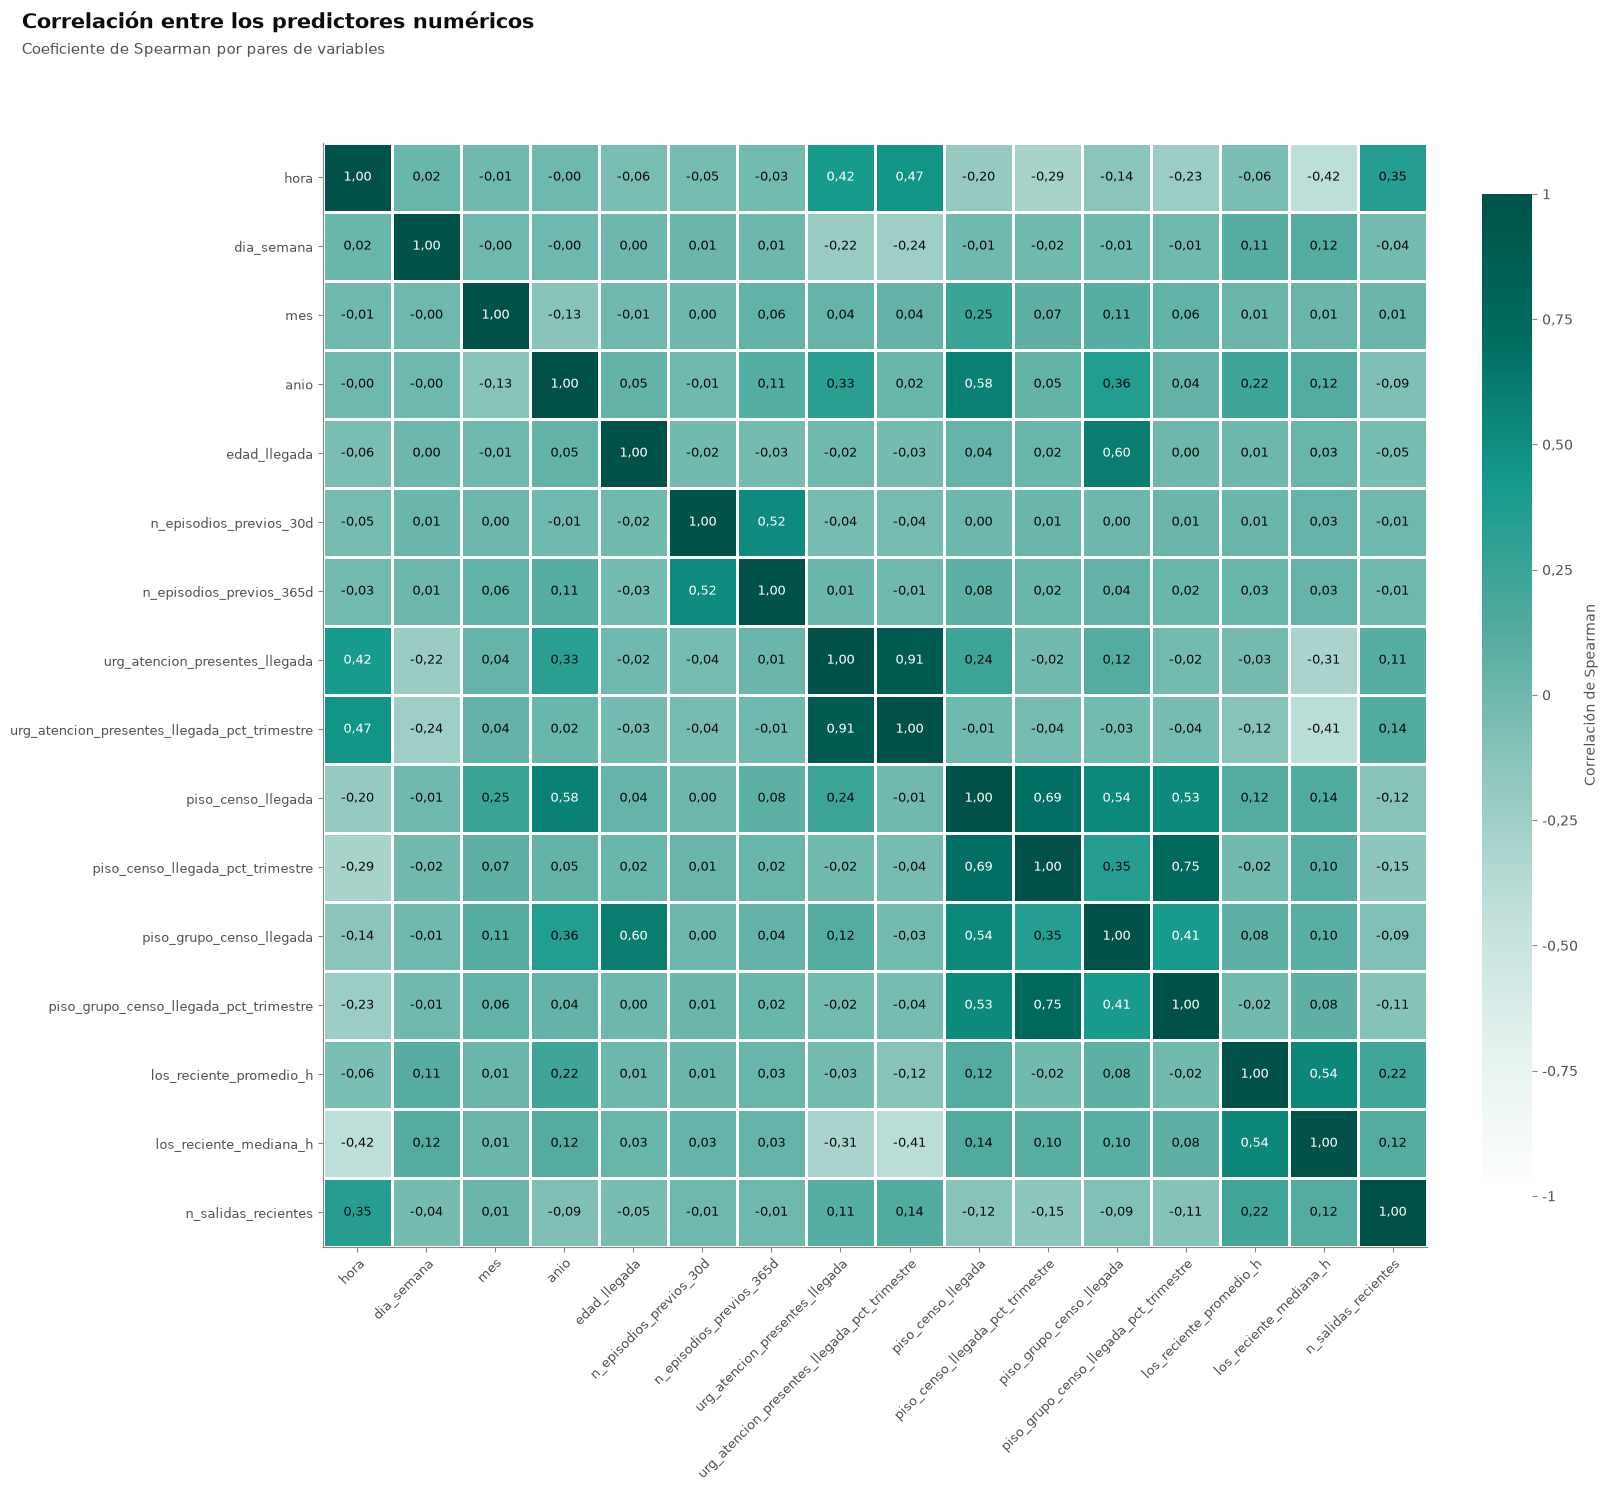

In [11]:
numericas = [c for c in PREDICTORES if car.tipo_variable(caracteristicas[c]) == 'numerica']
correlacion = caracteristicas[numericas].astype(float).corr(method='spearman')
fig, ax = plt.subplots(figsize=(16, 15))
car.heatmap_correlacion(ax, correlacion)
titulo_hallazgo(fig, 'Correlación entre los predictores numéricos', 'Coeficiente de Spearman por pares de variables')
guardar_figura(fig, '07_correlacion_spearman')
plt.show()

### 8.4 Historia completa y recortada

Mediana (numéricas) o % verdadero (booleanas) de cada variable en los episodios cuya ventana de historia queda completa y en los que queda recortada.

In [12]:
for dias in config.VENTANAS_HISTORIA_D:
    marca = f'historia_completa_{dias}d'
    comparacion = car.comparar_por_marca(caracteristicas, PREDICTORES + DESENLACES, marca)
    mostrar_tabla(tabla_segura(comparacion, decimales=2),
                  f'Características según la ventana de {dias} días: historia completa y recortada')

**Características según la ventana de 30 días: historia completa y recortada**

,estadistico,n_completa,valor_completa,n_recortada,valor_recortada
variable,,,,,
hosp_previa_30d,% verdadero,430.340,"1,52",12.258,"0,83"
hora,mediana,430.340,12,12.258,12
dia_semana,mediana,430.340,3,12.258,3
mes,mediana,430.340,6,12.258,1
anio,mediana,430.340,2.024,12.258,2.023
fin_de_semana,% verdadero,430.340,"22,39",12.258,"23,72"
festivo,% verdadero,430.340,"3,79",12.258,"5,07"
edad_llegada,mediana,430.340,28,12.258,28
pediatria,% verdadero,430.340,"27,23",12.258,"27,41"


**Características según la ventana de 365 días: historia completa y recortada**

,estadistico,n_completa,valor_completa,n_recortada,valor_recortada
variable,,,,,
hosp_previa_30d,% verdadero,292.328,"1,53",150.270,"1,45"
hora,mediana,292.328,12,150.270,12
dia_semana,mediana,292.328,3,150.270,3
mes,mediana,292.328,6,150.270,6
anio,mediana,292.328,2.025,150.270,2.023
fin_de_semana,% verdadero,292.328,"22,30",150.270,"22,69"
festivo,% verdadero,292.328,"3,72",150.270,"4,02"
edad_llegada,mediana,292.328,29,150.270,27
pediatria,% verdadero,292.328,"26,35",150.270,"28,96"


## 9. Exportación

Se guarda `data/interim/episodios_caracteristicas.parquet` (con el identificador interno del episodio; solo en `data/interim/`, ignorado por git). Las columnas se describen en `docs/diccionario_caracteristicas.md`.

In [13]:
caracteristicas = caracteristicas[list(car.NO_PREDICTORES) + list(config.ROLES_CARACTERISTICAS)]
caracteristicas.to_parquet(config.DATA_INTERIM / 'episodios_caracteristicas.parquet', index=False)
tabla_medidas({'parquet': 'data/interim/episodios_caracteristicas.parquet', 'filas': len(caracteristicas),
               'columnas': caracteristicas.shape[1], 'predictores': len(PREDICTORES),
               'desenlaces': len(DESENLACES), 'estratos, descriptivas y controles': len(OTRAS)}, 'Archivo exportado')

**Archivo exportado**

,medida,valor
0,parquet,data/interim/episodios_caracteristicas.parquet
1,filas,442.598
2,columnas,38
3,predictores,23
4,desenlaces,6
5,"estratos, descriptivas y controles",6
